# Regressão logística

Classificação de churn com a regressão logística regularizada (L2), avaliada com a validação cruzada estratificada de 10 folds comum a todos os algoritmos (`data/processed/folds.csv`).

**Pergunta central**: quanta regularização o modelo linear pede? Comparamos duas configurações que variam a força da regularização (**opção 1**: `C` 1 × 0,1) com uma grade de `C` de 0,001 a 100 (**opção 2**: 6 configurações), nas bases com e sem `inativo`. A opção 1 está contida na grade, e a comparação mostra se a busca mais ampla acrescenta algo além da variação entre folds.

## Como a regressão logística funciona

### Modelo

A regressão logística é um modelo **linear no log-odds**. Para um cliente com atributos $x = (x_1, \dots, x_d)$, ela calcula um escore linear e o transforma em probabilidade pela função sigmoide (logística):

$$z = w \cdot x + b = \sum_{j=1}^{d} w_j x_j + b, \qquad p = P(\text{churn} \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Equivalentemente, $\log\frac{p}{1 - p} = z$: o **log-odds** do churn é uma combinação linear dos atributos. O cliente é classificado como churn quando $p \ge 0{,}5$, ou seja, quando $z \ge 0$. A fronteira de decisão é, portanto, um hiperplano.

### Interpretação dos coeficientes

Aumentar $x_j$ em uma unidade, com os demais fixos, soma $w_j$ ao log-odds, ou seja, **multiplica a chance de churn por $e^{w_j}$** (o *odds ratio*).
- Nos atributos padronizados, "uma unidade" é **um desvio padrão**. Como os atributos de uso estão em `log1p`, um desvio corresponde a multiplicar o uso por um fator, e o efeito é relativo ("usar o dobro").
- Nos binários (0/1, com 1 = presença), $e^{w_j}$ é quanto **ter a característica** (reclamou, plano contratual, inativo) multiplica a chance de churn.
- $w_j > 0$ aumenta o risco; $w_j < 0$ reduz.

### Treino: máxima verossimilhança com pesos de classe e regularização

Cada cliente é tratado como um ensaio de Bernoulli com probabilidade $p_i$. Maximizar a verossimilhança equivale a minimizar a **entropia cruzada (log loss)**:

$$\ell_i = -\left[y_i \log p_i + (1 - y_i)\log(1 - p_i)\right].$$

Com `class_weight='balanced'`, cada cliente recebe o peso $v_i = \frac{n}{2\, n_{\text{classe}(i)}}$: os churns pesam ~3,2 e os não churns ~0,6, de modo que as duas classes contribuem igualmente para a perda. O scikit-learn minimiza

$$J(w, b) = \frac{1}{2}\lVert w \rVert^2 + C \sum_{i=1}^{n} v_i\, \ell_i.$$

- O termo $\frac{1}{2}\lVert w \rVert^2$ é a **penalidade L2**: encolhe os coeficientes em direção a zero, reduzindo a variância do modelo. O intercepto $b$ não é penalizado.
- **`C`** é o inverso da força da regularização ($C = 1/\lambda$): com `C` pequeno, a penalidade domina e os coeficientes encolhem muito (risco de subajuste); com `C` grande, o modelo se aproxima da regressão sem regularização.

O gradiente tem forma simples, porque $\partial \ell_i / \partial z_i = p_i - y_i$:

$$\nabla_w J = w + C \sum_i v_i (p_i - y_i)\, x_i, \qquad \frac{\partial J}{\partial b} = C \sum_i v_i (p_i - y_i).$$

$J$ é **convexa**: tem um único mínimo, e qualquer otimizador bem configurado chega à mesma solução. Por isso o resultado não depende de semente aleatória.

### Otimizador `lbfgs`

O `lbfgs` (*limited-memory BFGS*) é um método **quase-Newton**: usa o mesmo gradiente acima, mas aproxima a curvatura (a hessiana) a partir dos últimos gradientes e passos, e com isso escolhe a direção e o tamanho de cada passo melhor que a descida de gradiente simples. Converge em poucas dezenas de iterações nesta base; `max_iter=1000` é só uma folga.

### Por que a penalidade é indispensável aqui

As 5 colunas one-hot da idade sempre somam 1, exatamente como a coluna constante do intercepto. Sem penalidade, há infinitas combinações de coeficientes com a mesma previsão (somar uma constante às 5 faixas e subtraí-la do intercepto), e a solução não é única. A L2 escolhe, entre elas, a de menor norma, o que torna os coeficientes únicos e centrados: cada faixa de idade fica comparada à média, e não a uma faixa de referência arbitrária.

### Pseudocódigo

```
RegressaoLogistica(treino {(x_i, y_i)}, C, max_iter, tol):
    # pesos de classe "balanced"
    n_1 ← nº de churns ; n_0 ← nº de não churns ; n ← n_0 + n_1
    v_i ← n / (2·n_1) se y_i = 1, senão n / (2·n_0)

    w ← 0 (vetor de d posições) ; b ← 0
    para t = 1 até max_iter:
        para cada i:
            z_i ← w · x_i + b
            p_i ← 1 / (1 + exp(−z_i))
        # gradiente da função objetivo J(w, b)
        g_w ← w + C · Σ_i v_i (p_i − y_i) x_i
        g_b ← C · Σ_i v_i (p_i − y_i)
        se ‖(g_w, g_b)‖ < tol: parar                      # convergiu
        # passo: na descida de gradiente simples, (w, b) ← (w, b) − η (g_w, g_b);
        # o lbfgs troca η por uma direção quase-Newton com busca de linha
        (w, b) ← (w, b) − Passo(g_w, g_b, histórico de gradientes)

    devolver w, b

Prever(x):
    p ← 1 / (1 + exp(−(w · x + b)))
    devolver p      # probabilidade de churn; churn se p ≥ 0,5
```

## Por que a regressão logística neste problema

- **Linha de base linear e interpretável**: cada coeficiente é o efeito de um atributo no log-odds, com os demais fixos. É a forma mais direta de conferir H1 (há um atributo dominante?), H2 (quanto a reclamação aumenta a chance de churn?) e H6 (quanto o uso reduz?) com todos os atributos juntos.
- **Contraste com os modelos não lineares**: a análise exploratória indicou relações não lineares (faixa de cobrança, interação falhas × reclamação). Se a MLP e o XGBoost superarem a regressão logística, a diferença mede quanto essas não linearidades importam. A idade, que também não é monotônica, é tratada pelo one-hot.
- **Probabilidades bem comportadas**: o modelo é treinado diretamente na log loss, uma das métricas avaliadas.
- **Estável e rápido**: o problema de otimização é convexo, sem mínimos locais nem dependência de semente, e o treino leva frações de segundo.

## Pré-processamento necessário para a regressão logística

| etapa | onde é feita | por que a regressão logística precisa |
|---|---|---|
| padronização z-score das 8 numéricas | **dentro de cada fold** (`criar_preprocessador`, ajustado só no treino) | **obrigatória**. (1) A penalidade L2 soma os quadrados dos coeficientes: sem padronizar, um atributo de escala pequena precisaria de um coeficiente grande e seria mais punido, o que torna a regularização arbitrária. (2) Só com os atributos na mesma escala os coeficientes são comparáveis entre si, como medida de importância. (3) O otimizador converge melhor |
| `log1p` nos 6 atributos de uso | base inteira (`pre-processamento.ipynb`) | o efeito no log-odds passa a ser relativo ("usar o dobro"), o que combina com H6 (quem sai usa de 35% a 46% do que usa quem fica), e a cauda longa deixa de dominar a padronização e o ajuste |
| **one-hot da idade** (5 colunas) | base inteira | **necessário só neste algoritmo**. Como número, a idade teria um único coeficiente ("quanto mais velho, mais ou menos churn"), mas o churn é quase nulo nos dois extremos. Com uma coluna por faixa, cada grupo tem seu coeficiente. As 5 ficam, sem categoria de referência, porque a L2 resolve a colinearidade com o intercepto |
| binários em 0/1, sem padronizar | base inteira (recodificação 1 = presença) | cada coeficiente é diretamente o efeito de ter a característica (reclamou, plano contratual, inativo) |
| pesos de classe | `class_weight='balanced'` (calculado no treino de cada fold) | sem eles, os 84% de não churn dominam a perda e o recall cai |

**Clientes sem uso**: os 107 clientes com zero em todas as colunas de uso ficam em torno de −4 desvios depois da padronização. Para um modelo linear, eles estão no extremo da reta "mais uso, menos churn" e recebem risco alto, o que é coerente com os 52% de churn do grupo.

## Parâmetros

**Variado**:

| parâmetro | valores | papel e justificativa |
|---|---|---|
| `C` | 0,001; 0,01; 0,1; 1; 10; 100 | inverso da força da L2 em $J = \frac{1}{2}\lVert w\rVert^2 + C \sum v_i \ell_i$. A grade em escala log vai de uma regularização forte (coeficientes muito encolhidos, possível subajuste) a uma quase nula. Com 2850 clientes e 16 atributos, espera-se que o desempenho se estabilize a partir de `C` ≈ 0,1–1 |

- **Opção 1**: `C1` (o padrão) e `C0.1` (regularização 10× mais forte).
- **Opção 2**: a grade completa (6 configurações), que contém as duas da opção 1.

**Fixos**:

| parâmetro | valor | justificativa |
|---|---|---|
| `penalty` | `l2` | encolhe todos os coeficientes sem zerá-los; necessária por causa do one-hot (ver acima) e adequada aos atributos correlacionados (segundos × ligações), cujo efeito ela divide de forma estável |
| `solver` | `lbfgs` | quase-Newton, padrão do scikit-learn para L2 |
| `class_weight` | `balanced` | pesos $v_i = n / (2\,n_{\text{classe}})$ na perda |
| `max_iter` | 1000 | folga para a convergência (o padrão, 100, pode não bastar com `C` grande) |
| `fit_intercept` | `True` | o intercepto absorve a taxa básica de churn e não é penalizado |

Total: 6 configurações × 2 bases = **12 rodadas de 10 folds**, mais 2 rodadas da configuração escolhida **sem `class_weight`** (seção "Efeito do desbalanceamento").

## Configuração

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from comum import (METRICAS, N_CHURN, N_LINHAS, RESULTS_DIR, avaliar, carregar_base,
                   carregar_folds, criar_preprocessador, nome_base, salvar_resultados,
                   registrar_escolhida, salvar_tabela, tabela_desbalanceamento)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

VALORES_C = [0.001, 0.01, 0.1, 1, 10, 100]
MAX_ITER = 1000


def nome_config(c):
    return f'C{c}'


GRADE = {nome_config(c): c for c in VALORES_C}
OPCAO_1 = ['C1', 'C0.1']
assert set(OPCAO_1) <= set(GRADE)
print(f'{len(GRADE)} configurações × 2 bases = {len(GRADE) * 2} rodadas')

6 configurações × 2 bases = 12 rodadas


In [2]:
def criar_rl(c, com_status, pesos='balanced'):
    # devolve a função que o avaliar chama em cada fold (pipeline novo, sem ajuste)
    # pesos=None só na seção do desbalanceamento
    def criar(y_treino):
        return Pipeline([
            ('prep', criar_preprocessador(com_status)),
            ('rl', LogisticRegression(
                penalty='l2',
                C=c,
                solver='lbfgs',
                class_weight=pesos,
                max_iter=MAX_ITER,
                fit_intercept=True,
            )),
        ])
    return criar

## Dados e folds

As duas bases têm as mesmas linhas e o mesmo `churn`, então usam os mesmos folds. A idade fica em one-hot (5 colunas), como está na base.

In [3]:
bases = {com_status: carregar_base(com_status) for com_status in [True, False]}
y = bases[True][1]
assert np.array_equal(y, bases[False][1])
folds = carregar_folds(y)

for com_status, (X, _) in bases.items():
    print(f'{nome_base(com_status)}: {X.shape[1]} atributos')

com-status: 16 atributos
sem-status: 15 atributos


## Execução da grade

In [4]:
linhas, resultados = [], {}
for com_status, (X, y) in bases.items():
    base = nome_base(com_status)
    for config, c in GRADE.items():
        r = avaliar(criar_rl(c, com_status), X, y, folds)
        assert r['matriz'].sum() == N_LINHAS
        assert r['matriz'][1].sum() == N_CHURN
        n_iter = [int(pipe[-1].n_iter_[0]) for pipe in r['modelos']]
        assert max(n_iter) < MAX_ITER, f'{config} ({base}) não convergiu'

        resultados[(config, base)] = r
        linhas.append(r['por_fold'].reset_index().assign(
            base=base, config=config, C=c, opcao_1=config in OPCAO_1, n_iter=n_iter))

grade = pd.concat(linhas, ignore_index=True)
assert len(grade) == len(GRADE) * 2 * 10
grade.to_csv(RESULTS_DIR / 'rl-grade-metricas.csv', index=False)

c:\7-periodo\mineracao-dados\trabalho-final\src\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\7-periodo\mineracao-dados\trabalho-final\src\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:

## Resumo por configuração

Média ± desvio nos 10 folds, ordenado por PR-AUC. A coluna `opção 1` marca as duas configurações da opção 1.

In [5]:
CHAVES = ['base', 'config', 'C', 'opcao_1']
resumo = grade.groupby(CHAVES)[METRICAS + ['n_iter']].agg(['mean', 'std'])
resumo.columns = [f'{m}_{"media" if e == "mean" else "desvio"}' for m, e in resumo.columns]
resumo = resumo.reset_index()
resumo.to_csv(RESULTS_DIR / 'rl-grade-resumo.csv', index=False)


def formatar(res):
    t = res[['config']].copy()
    t['opção 1'] = res['opcao_1'].map({True: '✔', False: ''})
    for m in METRICAS:
        t[m] = res[f'{m}_media'].map('{:.3f}'.format) + ' ± ' + res[f'{m}_desvio'].map('{:.3f}'.format)
    t['iterações'] = res['n_iter_media'].round().astype(int)
    return t.reset_index(drop=True)


for base in ['sem-status', 'com-status']:
    print(f'\n=== base {base} (ordenada por PR-AUC) ===')
    tab = formatar(resumo[resumo['base'] == base].sort_values('pr_auc_media', ascending=False))
    display(tab)
    salvar_tabela(tab, f'rl-tab-resumo-{base}')


=== base sem-status (ordenada por PR-AUC) ===


,config,opção 1,recall,especificidade,f1_macro,log_loss,pr_auc,iterações
0,C100,,0.852 ± 0.070,0.854 ± 0.022,0.777 ± 0.028,0.339 ± 0.037,0.765 ± 0.075,54
1,C10,,0.849 ± 0.072,0.854 ± 0.022,0.776 ± 0.029,0.339 ± 0.036,0.765 ± 0.075,46
2,C1,✔,0.849 ± 0.072,0.855 ± 0.024,0.777 ± 0.030,0.339 ± 0.035,0.764 ± 0.077,47
3,C0.1,✔,0.840 ± 0.082,0.855 ± 0.023,0.774 ± 0.033,0.351 ± 0.032,0.748 ± 0.082,25
4,C0.01,,0.836 ± 0.092,0.843 ± 0.019,0.761 ± 0.030,0.427 ± 0.028,0.614 ± 0.102,13
5,C0.001,,0.755 ± 0.082,0.807 ± 0.023,0.706 ± 0.027,0.549 ± 0.017,0.501 ± 0.077,7



=== base com-status (ordenada por PR-AUC) ===


,config,opção 1,recall,especificidade,f1_macro,log_loss,pr_auc,iterações
0,C100,,0.854 ± 0.064,0.857 ± 0.024,0.781 ± 0.026,0.332 ± 0.036,0.765 ± 0.069,54
1,C10,,0.854 ± 0.064,0.857 ± 0.025,0.781 ± 0.026,0.332 ± 0.036,0.765 ± 0.069,46
2,C1,✔,0.856 ± 0.063,0.859 ± 0.024,0.783 ± 0.024,0.332 ± 0.035,0.763 ± 0.069,48
3,C0.1,✔,0.865 ± 0.063,0.859 ± 0.025,0.786 ± 0.027,0.340 ± 0.032,0.747 ± 0.069,26
4,C0.01,,0.863 ± 0.075,0.847 ± 0.024,0.773 ± 0.028,0.404 ± 0.026,0.626 ± 0.096,14
5,C0.001,,0.816 ± 0.071,0.812 ± 0.022,0.728 ± 0.022,0.533 ± 0.017,0.519 ± 0.076,8


### Métricas em função de `C`

Média ± desvio nos folds, com `C` em escala log. As linhas tracejadas marcam a opção 1 (`C` = 0,1 e 1).

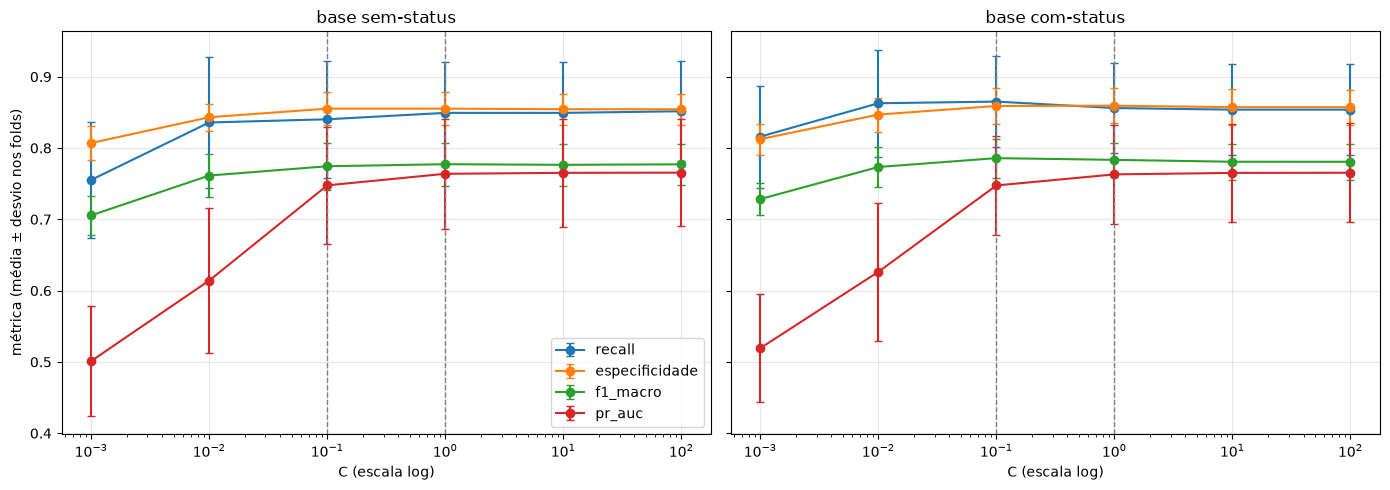

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, base in zip(eixos, ['sem-status', 'com-status']):
    sub = resumo[resumo['base'] == base].sort_values('C')
    for m in METRICAS:
        if m == 'log_loss':
            continue  # outra escala; aparece na tabela
        ax.errorbar(sub['C'], sub[f'{m}_media'], yerr=sub[f'{m}_desvio'], marker='o', capsize=3, label=m)
    for c in [0.1, 1]:
        ax.axvline(c, color='gray', ls='--', lw=1)
    ax.set_xscale('log')
    ax.set_xlabel('C (escala log)')
    ax.set_title(f'base {base}')
    ax.grid(alpha=0.3)
eixos[0].set_ylabel('métrica (média ± desvio nos folds)')
eixos[0].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'rl-curva-C.png', dpi=150, bbox_inches='tight')
plt.show()

## Opção 1 × opção 2

A melhor configuração da grade (opção 2) é escolhida pela maior PR-AUC média na **base sem `inativo`**, que não tem a suspeita de vazamento, e comparada **fold a fold** com cada configuração da opção 1 (diferença opção 2 − opção 1). Se a diferença média for menor que o seu desvio, a busca mais ampla não ganhou nada além da variação entre folds.

**Parcimônia**: entre as configurações cuja PR-AUC fica a menos de um desvio da melhor, a escolhida é a de **menor `C`**, a mais regularizada, isto é, o modelo mais simples.

In [7]:
ref = resumo[resumo['base'] == 'sem-status']
melhor_2 = ref.sort_values('pr_auc_media', ascending=False).iloc[0]

limite = melhor_2['pr_auc_media'] - melhor_2['pr_auc_desvio']
candidatas = ref[ref['pr_auc_media'] >= limite]
escolhida = candidatas.sort_values('C').iloc[0]

print(f'melhor da grade (opção 2): {melhor_2["config"]} '
      f'(PR-AUC {melhor_2["pr_auc_media"]:.3f} ± {melhor_2["pr_auc_desvio"]:.3f})')
print(f'configurações a menos de um desvio da melhor: {list(candidatas["config"])}')
print(f'escolhida pela parcimônia: {escolhida["config"]}')

linhas_cmp = []
for base in ['sem-status', 'com-status']:
    b = grade[(grade['base'] == base) & (grade['config'] == melhor_2['config'])].set_index('fold')
    for config_1 in OPCAO_1:
        a = grade[(grade['base'] == base) & (grade['config'] == config_1)].set_index('fold')
        linha = {'base': base, 'comparação': f'{melhor_2["config"]} (opção 2) − {config_1} (opção 1)'}
        for m in METRICAS:
            dif = b[m] - a[m]
            linha[m] = f'{dif.mean():+.3f} ± {dif.std():.3f}'
        linha['folds com PR-AUC maior (opção 2)'] = int((b['pr_auc'] > a['pr_auc']).sum())
        linhas_cmp.append(linha)
tab = pd.DataFrame(linhas_cmp)
salvar_tabela(tab, 'rl-tab-opcao1-x-opcao2')
tab

melhor da grade (opção 2): C100 (PR-AUC 0.765 ± 0.075)
configurações a menos de um desvio da melhor: ['C0.1', 'C1', 'C10', 'C100']
escolhida pela parcimônia: C0.1


,base,comparação,recall,especificidade,f1_macro,log_loss,pr_auc,folds com PR-AUC maior (opção 2)
0,sem-status,C100 (opção 2) − C1 (opção 1),+0.002 ± 0.007,-0.001 ± 0.003,-0.000 ± 0.004,+0.001 ± 0.002,+0.002 ± 0.004,7
1,sem-status,C100 (opção 2) − C0.1 (opção 1),+0.011 ± 0.019,-0.001 ± 0.010,+0.003 ± 0.011,-0.012 ± 0.007,+0.018 ± 0.013,9
2,com-status,C100 (opção 2) − C1 (opção 1),-0.002 ± 0.013,-0.002 ± 0.004,-0.003 ± 0.007,+0.000 ± 0.002,+0.002 ± 0.003,8
3,com-status,C100 (opção 2) − C0.1 (opção 1),-0.011 ± 0.019,-0.002 ± 0.005,-0.005 ± 0.007,-0.008 ± 0.005,+0.018 ± 0.013,9


## Configurações finais

As duas da opção 1, a melhor da grade e a escolhida pela parcimônia (sem repetição), nas duas bases. Elas vão para o notebook de comparação via `salvar_resultados`.

In [8]:
FINAIS = list(dict.fromkeys(OPCAO_1 + [melhor_2['config'], escolhida['config']]))
for config in FINAIS:
    for com_status in [True, False]:
        salvar_resultados(resultados[(config, nome_base(com_status))], 'rl', config, com_status)
print('salvas:', FINAIS)
registrar_escolhida('rl', escolhida['config'])

salvas: ['C1', 'C0.1', 'C100']


### Matrizes de confusão

Somadas nos 10 folds.

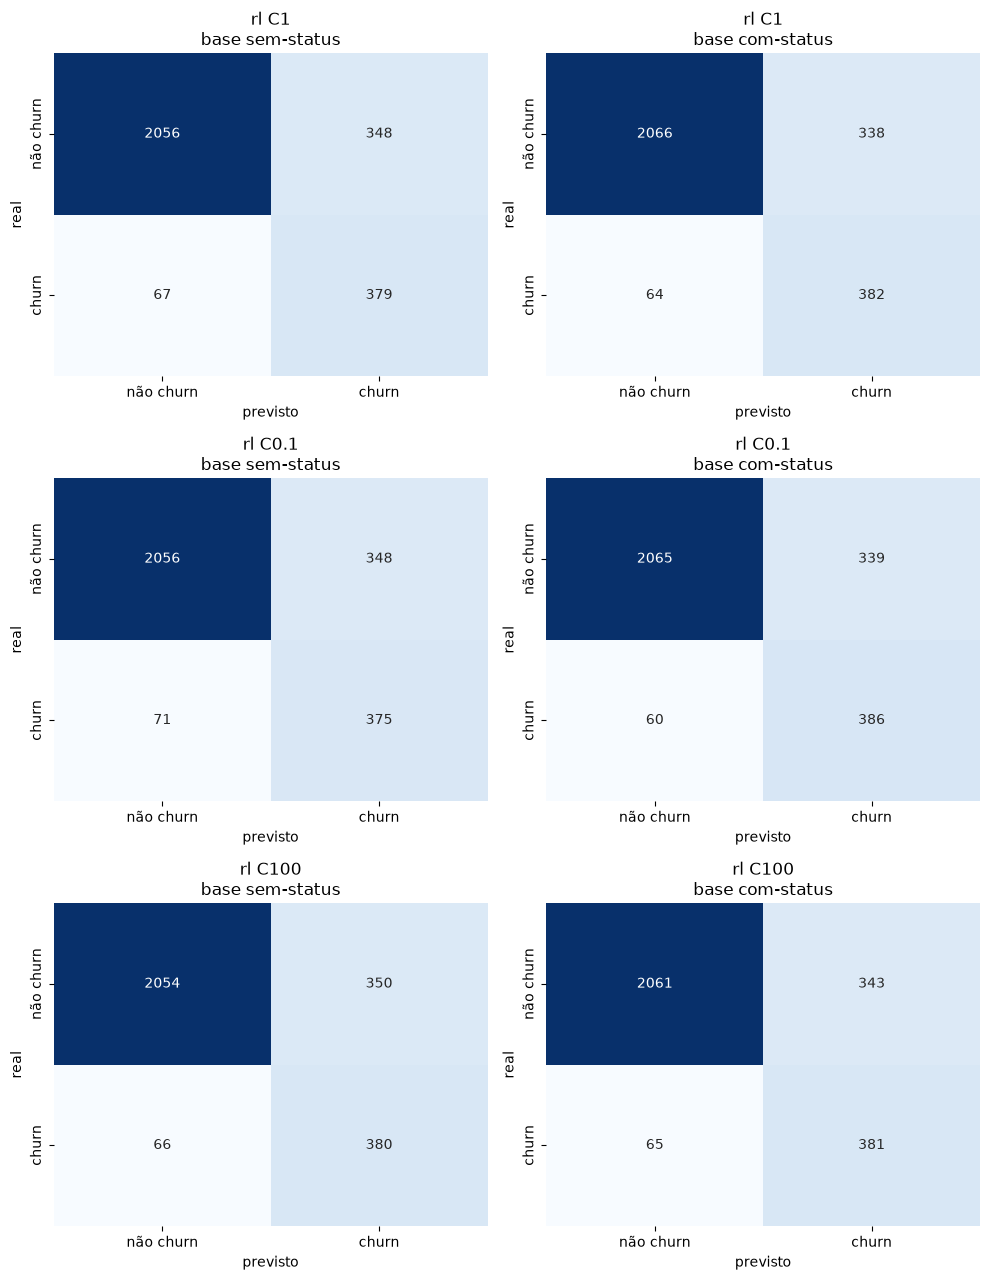

In [9]:
fig, eixos = plt.subplots(len(FINAIS), 2, figsize=(10, 4.3 * len(FINAIS)), squeeze=False)
for i, config in enumerate(FINAIS):
    for j, base in enumerate(['sem-status', 'com-status']):
        ax = eixos[i, j]
        sns.heatmap(resultados[(config, base)]['matriz'], annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=['não churn', 'churn'], yticklabels=['não churn', 'churn'], ax=ax)
        ax.set_title(f'rl {config}\nbase {base}')
        ax.set_xlabel('previsto')
        ax.set_ylabel('real')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'rl-matrizes-confusao.png', dpi=150, bbox_inches='tight')
plt.show()

### Comparação com as regras de referência e efeito do `inativo`

In [10]:
tabela = [
    {'modelo': 'regra: reclamou → churn', 'base': '—', 'recall': 0.426, 'especificidade': 0.983},
    {'modelo': 'regra: inativo → churn', 'base': '—', 'recall': 0.729, 'especificidade': 0.851},
]
for config in FINAIS:
    for base in ['sem-status', 'com-status']:
        lin = resumo[(resumo['config'] == config) & (resumo['base'] == base)].iloc[0]
        tabela.append({'modelo': f'rl {config}', 'base': base,
                       **{m: round(lin[f'{m}_media'], 3) for m in METRICAS}})
tab = pd.DataFrame(tabela)
display(tab)
salvar_tabela(tab, 'rl-tab-referencia')

efeito = []
for config in FINAIS:
    com = resumo[(resumo['config'] == config) & (resumo['base'] == 'com-status')].iloc[0]
    sem = resumo[(resumo['config'] == config) & (resumo['base'] == 'sem-status')].iloc[0]
    efeito.append({'config': config, **{f'dif {m} (com − sem)': round(com[f'{m}_media'] - sem[f'{m}_media'], 3)
                                        for m in METRICAS}})
tab = pd.DataFrame(efeito)
display(tab)
salvar_tabela(tab, 'rl-tab-efeito-inativo')

,modelo,base,recall,especificidade,f1_macro,log_loss,pr_auc
0,regra: reclamou → churn,—,0.426,0.983,NaN,NaN,NaN
1,regra: inativo → churn,—,0.729,0.851,NaN,NaN,NaN
2,rl C1,sem-status,0.849,0.855,0.777,0.339,0.764
3,rl C1,com-status,0.856,0.859,0.783,0.332,0.763
4,rl C0.1,sem-status,0.840,0.855,0.774,0.351,0.748
5,rl C0.1,com-status,0.865,0.859,0.786,0.340,0.747
6,rl C100,sem-status,0.852,0.854,0.777,0.339,0.765
7,rl C100,com-status,0.854,0.857,0.781,0.332,0.765


,config,dif recall (com − sem),dif especificidade (com − sem),dif f1_macro (com − sem),dif log_loss (com − sem),dif pr_auc (com − sem)
0,C1,0.007,0.004,0.006,-0.007,-0.001
1,C0.1,0.025,0.004,0.011,-0.011,-0.000
2,C100,0.002,0.003,0.004,-0.007,-0.000


WindowsPath('C:/7-periodo/mineracao-dados/trabalho-final/data/results/modelagem/rl-tab-efeito-inativo.png')

## Coeficientes

Coeficientes de cada um dos 10 modelos (um por fold), sobre os atributos padronizados (numéricos) ou 0/1 (binários e one-hot), para todas as configurações. Os coeficientes da configuração escolhida são resumidos em média ± desvio, com o *odds ratio* $e^{w}$ da média: quanto um desvio a mais (numéricos) ou ter a característica (binários) multiplica a chance de churn.

Leitura para as hipóteses: **H1** (há um atributo isolado decisivo?) se vê no tamanho relativo dos coeficientes; **H2** no coeficiente de `reclamacao`; **H6** nos atributos de uso (`qtd_ligacoes`, `segundos_uso`, `qtd_sms`, `numeros_distintos`, `valor_cliente`).

media                desvio            odds_ratio  \
base              com-status sem-status com-status sem-status com-status   
atributo                                                                   
reclamacao             2.600      2.719      0.059      0.059     13.466   
qtd_ligacoes          -1.214     -1.536      0.030      0.028      0.297   
falhas_ligacao         1.008      1.190      0.028      0.029      2.741   
faixa_cobranca        -0.666     -1.112      0.023      0.021      0.514   
idade_55              -0.604     -0.845      0.042      0.040      0.546   
idade_15              -0.569     -0.702      0.024      0.031      0.566   
idade_30               0.374      0.558      0.039      0.038      1.454   
idade_25               0.507      0.535      0.067      0.065      1.661   
idade_45               0.284      0.447      0.052      0.053      1.328   
segundos_uso           0.394      0.446      0.047      0.048      1.482   
valor_cliente         -0.209     -0.404      0.040      0.039      0.811   
qtd_sms               -0.315     -0.243      0.030      0.029      0.730   
plano_contratual      -0.254     -0.215      0.063      0.059      0.775   
meses_assinatura      -0.342     -0.185      0.019      0.018      0.710   
numeros_distintos     -0.063      0.036      0.035      0.033      0.939   

                              
base              sem-status  
atributo                      
reclamacao            15.171  
qtd_ligacoes           0.215  
falhas_ligacao         3.286  
faixa_cobranca         0.329  
idade_55               0.430  
idade_15               0.496  
idade_30               1.747  
idade_25               1.707  
idade_45               1.564  
segundos_uso           1.562  
valor_cliente          0.668  
qtd_sms                0.784  
plano_contratual       0.806  
meses_assinatura       0.831  
numeros_distintos      1.037

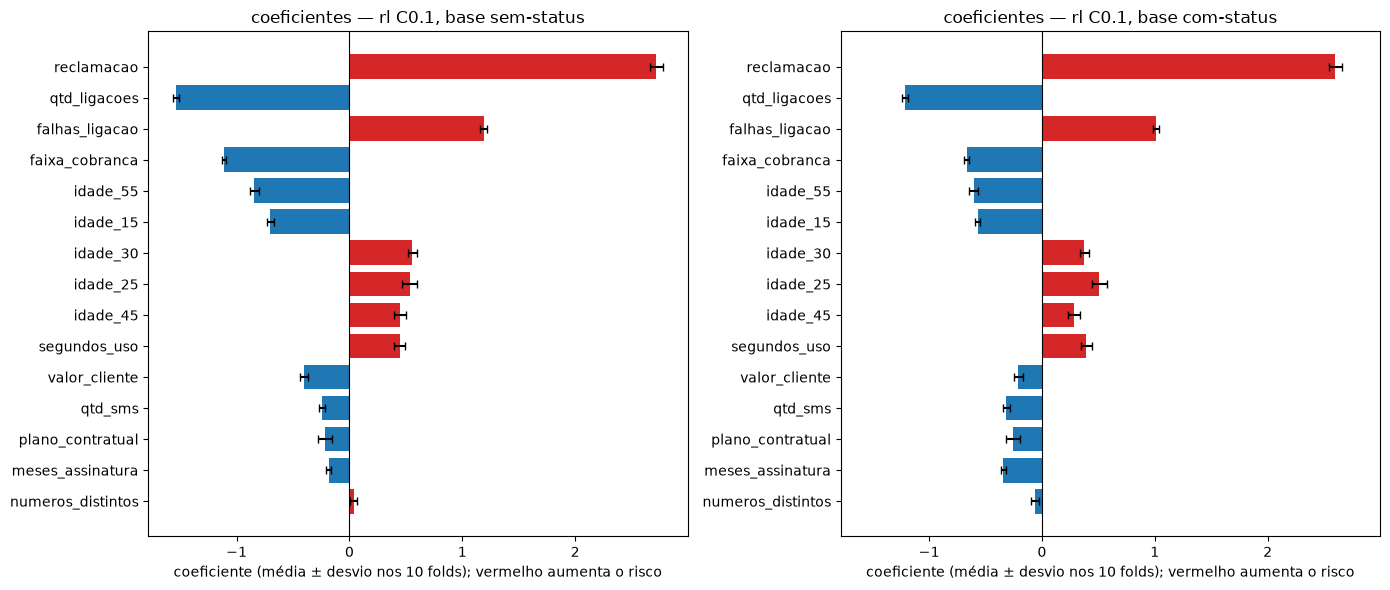

In [11]:
linhas_coef = []
for (config, base), r in resultados.items():
    for k, pipe in enumerate(r['modelos']):
        nomes = [n.split('__', 1)[1] for n in pipe[:-1].get_feature_names_out()]
        for atributo, w in zip(nomes, pipe[-1].coef_[0]):
            linhas_coef.append({'config': config, 'C': GRADE[config], 'base': base, 'fold': k,
                                'atributo': atributo, 'coef': w})
coeficientes = pd.DataFrame(linhas_coef)
coeficientes.to_csv(RESULTS_DIR / 'rl-coeficientes.csv', index=False)

resumo_coef = (coeficientes[coeficientes['config'] == escolhida['config']]
               .groupby(['base', 'atributo'])['coef'].agg(['mean', 'std'])
               .rename(columns={'mean': 'media', 'std': 'desvio'}).reset_index())
resumo_coef['odds_ratio'] = np.exp(resumo_coef['media'])

tabela_coef = resumo_coef.pivot(index='atributo', columns='base', values=['media', 'desvio', 'odds_ratio'])
ordem = resumo_coef[resumo_coef['base'] == 'sem-status'].set_index('atributo')['media'].abs().sort_values(ascending=False).index
tab = tabela_coef.reindex(ordem).round(3)
display(tab)
salvar_tabela(tab, 'rl-tab-coeficientes')

fig, eixos = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, base in zip(eixos, ['sem-status', 'com-status']):
    sub = resumo_coef[resumo_coef['base'] == base].set_index('atributo').reindex(ordem[::-1]).dropna()
    cores = ['tab:red' if w > 0 else 'tab:blue' for w in sub['media']]
    ax.barh(sub.index, sub['media'], xerr=sub['desvio'], color=cores, capsize=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'coeficientes — rl {escolhida["config"]}, base {base}')
    ax.set_xlabel('coeficiente (média ± desvio nos 10 folds); vermelho aumenta o risco')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'rl-coeficientes.png', dpi=150, bbox_inches='tight')
plt.show()

### Estabilidade do par redundante segundos × ligações

`segundos_uso` e `qtd_ligacoes` têm r = 0,925 depois do log. Num modelo linear, atributos tão correlacionados podem "dividir" o mesmo efeito de muitas formas, e os coeficientes individuais ficam instáveis, ainda que a soma deles seja estável. A L2 reduz essa instabilidade, tanto mais quanto menor o `C`.

A figura mostra os dois coeficientes (média ± desvio nos folds) e a soma deles em função de `C`, na base sem `inativo`.

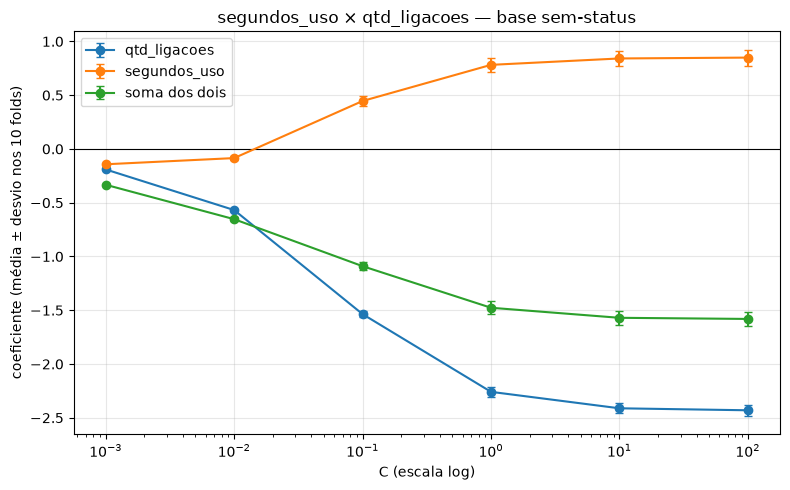

mean                                     std               \
atributo qtd_ligacoes segundos_uso soma dos dois qtd_ligacoes segundos_uso   
C                                                                            
0.001          -0.191       -0.143        -0.333        0.003        0.004   
0.010          -0.568       -0.085        -0.653        0.009        0.018   
0.100          -1.536        0.446        -1.090        0.028        0.048   
1.000          -2.259        0.782        -1.477        0.046        0.066   
10.000         -2.412        0.841        -1.570        0.047        0.073   
100.000        -2.430        0.849        -1.581        0.051        0.074   

                        
atributo soma dos dois  
C                       
0.001            0.006  
0.010            0.018  
0.100            0.038  
1.000            0.061  
10.000           0.065  
100.000          0.067

WindowsPath('C:/7-periodo/mineracao-dados/trabalho-final/data/results/modelagem/rl-tab-par-redundante.png')

In [12]:
par = coeficientes[(coeficientes['base'] == 'sem-status')
                   & coeficientes['atributo'].isin(['segundos_uso', 'qtd_ligacoes'])]
soma = (par.groupby(['C', 'fold'])['coef'].sum().reset_index().assign(atributo='soma dos dois'))
par = pd.concat([par[['C', 'fold', 'atributo', 'coef']], soma], ignore_index=True)

estat = par.groupby(['atributo', 'C'])['coef'].agg(['mean', 'std']).reset_index()
fig, ax = plt.subplots(figsize=(8, 5))
for atributo, sub in estat.groupby('atributo'):
    ax.errorbar(sub['C'], sub['mean'], yerr=sub['std'], marker='o', capsize=3, label=atributo)
ax.axhline(0, color='black', lw=0.8)
ax.set_xscale('log')
ax.set_xlabel('C (escala log)')
ax.set_ylabel('coeficiente (média ± desvio nos 10 folds)')
ax.set_title('segundos_uso × qtd_ligacoes — base sem-status')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'rl-par-redundante.png', dpi=150, bbox_inches='tight')
plt.show()

tab = estat.pivot(index='C', columns='atributo', values=['mean', 'std']).round(3)
display(tab)
salvar_tabela(tab, 'rl-tab-par-redundante')

## Efeito do desbalanceamento

A configuração escolhida pela parcimônia é treinada de novo **sem `class_weight`** (todos os clientes com peso 1), com os mesmos folds, e comparada fold a fold à versão `balanced`.

O que se espera: sem pesos, a perda é dominada pelos 84% de não churn, o intercepto fica mais negativo e menos clientes passam do limiar 0,5. O **recall** deve cair e a **especificidade** subir. Num modelo linear, os pesos de classe mudam sobretudo o intercepto, de modo que a ordem dos clientes por probabilidade quase não muda e a **PR-AUC** deve ficar praticamente igual. O **log loss** deve melhorar, porque as probabilidades passam a refletir a proporção real de churn. Se for isso, o desbalanceamento afeta o **ponto de operação**, e não a capacidade de separar as classes.

In [13]:
linhas_desb = []
for com_status, (X, y) in bases.items():
    base = nome_base(com_status)
    r_sem = avaliar(criar_rl(GRADE[escolhida['config']], com_status, pesos=None), X, y, folds)
    assert r_sem['matriz'].sum() == N_LINHAS
    salvar_resultados(r_sem, 'rl', f'{escolhida["config"]}_sem-pesos', com_status)
    linhas_desb += tabela_desbalanceamento(resultados[(escolhida['config'], base)], r_sem, base)
print(f'configuração: {escolhida["config"]}')
tab = pd.DataFrame(linhas_desb)
salvar_tabela(tab, 'rl-tab-desbalanceamento')
tab

c:\7-periodo\mineracao-dados\trabalho-final\src\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\7-periodo\mineracao-dados\trabalho-final\src\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:

configuração: C0.1


,base,versão,recall,especificidade,f1_macro,log_loss,pr_auc,FN (churns perdidos),FP (falsos alarmes)
0,com-status,com tratamento,0.865 ± 0.063,0.859 ± 0.025,0.786 ± 0.027,0.340 ± 0.032,0.747 ± 0.069,60.0,339.0
1,com-status,sem tratamento,0.533 ± 0.088,0.967 ± 0.013,0.782 ± 0.046,0.231 ± 0.029,0.757 ± 0.072,208.0,79.0
2,com-status,diferença (sem − com),-0.332 ± 0.046,+0.108 ± 0.024,-0.004 ± 0.040,-0.110 ± 0.026,+0.010 ± 0.005,NaN,NaN
3,sem-status,com tratamento,0.840 ± 0.082,0.855 ± 0.023,0.774 ± 0.033,0.351 ± 0.032,0.748 ± 0.082,71.0,348.0
4,sem-status,sem tratamento,0.513 ± 0.101,0.973 ± 0.013,0.780 ± 0.055,0.237 ± 0.031,0.758 ± 0.081,217.0,64.0
5,sem-status,diferença (sem − com),-0.327 ± 0.056,+0.118 ± 0.023,+0.006 ± 0.041,-0.114 ± 0.020,+0.010 ± 0.007,NaN,NaN


## Conclusões

- **Regularização**: o desempenho se estabiliza a partir de `C` = 0,1. Na base sem `inativo`, a PR-AUC é 0,748 com `C` = 0,1, 0,764 com 1 e 0,765 com 10 e 100. Abaixo disso há subajuste: com `C` = 0,01 a PR-AUC cai para 0,614, e com 0,001 para 0,501 (recall 0,755, log loss 0,549). A penalidade forte encolhe os coeficientes até apagar boa parte do efeito do uso: a soma dos coeficientes de segundos e ligações vai de −1,58 (`C` = 100) para −0,33 (`C` = 0,001).
- **Opção 1 × 2**: a grade não trouxe ganho relevante. A melhor configuração (`C100`) fica +0,002 ± 0,004 acima de `C1` em PR-AUC. Contra `C0.1`, ganha +0,018 ± 0,013, em 9 de 10 folds: um ganho consistente, porém bem menor que o desvio da PR-AUC entre folds (0,075). Por isso a parcimônia ficou com `C0.1`, o modelo mais regularizado entre os que empatam. A regra é tolerante (na comparação pareada, `C1` seria um pouco melhor que `C0.1`), mas a diferença não muda nenhuma conclusão.
- **Modelo linear × não lineares**: a regressão logística fica bem atrás. Na base sem `inativo`, a PR-AUC é 0,748, contra 0,932 do XGBoost e da MLP (−0,185 ± 0,063 em relação ao XGBoost, que vence em 10 de 10 folds). Ela perde 71 churns e dá 348 falsos alarmes, contra 38 e 100 do XGBoost. A distância mede o peso das não linearidades e interações neste problema: idade, faixa de cobrança, falhas em relação ao uso e o limiar de uso zero.
- **`inativo`**: quase nenhum efeito nas métricas. Na `C0.1`, a base com `inativo` sobe o recall em 0,025 e mantém a PR-AUC (−0,000). Os coeficientes mudam: com `inativo`, os de `qtd_ligacoes` (−1,54 → −1,21), `faixa_cobranca` (−1,11 → −0,67) e `valor_cliente` (−0,40 → −0,21) encolhem. O atributo absorve parte do efeito do uso, ou seja, repete informação que já está nas colunas de uso.
- **Referência**: com recall 0,840 e especificidade 0,855 (sem `inativo`), a regressão logística supera por pouco a regra "inativo → churn" (0,729 e 0,851) nas duas medidas. É a menor vantagem entre os algoritmos que superam a regra.
- **Desbalanceamento**: sem `class_weight`, a regressão logística é o algoritmo que mais perde recall: de 0,840 para 0,513 (−0,327 ± 0,056; de 71 para 217 churns perdidos). A especificidade sobe de 0,855 para 0,973 (de 348 para 64 falsos alarmes) e o log loss melhora de 0,351 para 0,237. A PR-AUC fica praticamente igual (+0,010 ± 0,007), como esperado de um modelo em que os pesos mudam quase só o intercepto, e o F1 macro também (+0,006).
- **Hipóteses**: os coeficientes da `C0.1` (base sem `inativo`) confirmam H1, H2 e H6.
  - H1: `reclamacao` tem o maior coeficiente (2,72), mas outros têm peso da mesma ordem: `qtd_ligacoes` (−1,54), `falhas_ligacao` (+1,19) e `faixa_cobranca` (−1,11). Nenhum atributo decide sozinho.
  - H2: com os demais atributos fixos, reclamar multiplica a chance de churn por 15,2 (odds ratio).
  - H6: mais uso, menos risco. Cada desvio a mais em `qtd_ligacoes` multiplica a chance por 0,215; `valor_cliente` (0,668) e `qtd_sms` (0,784) vão na mesma direção. O coeficiente positivo de `segundos_uso` (+0,45) vem da redundância com as ligações (ver o último item).
  - H4: com as ligações fixas, mais falhas aumentam o risco (odds ratio 3,29). Como os dois atributos estão em log, o par de coeficientes (+1,19 nas falhas e −1,54 nas ligações) aproxima o efeito da taxa de falha da análise exploratória, sem que ela tenha sido criada como atributo.
  - Idade: os extremos têm coeficientes negativos (`idade_55` −0,85, `idade_15` −0,70) e as faixas do meio, positivos (25 anos +0,54, 30 anos +0,56, 45 anos +0,45). O one-hot captou o churn baixo nos extremos.
- **Redundância**: entre folds, os coeficientes de segundos e ligações são estáveis (desvios de 0,003 a 0,074 em todos os `C`). A instabilidade aparece quando o `C` muda: `segundos_uso` troca de sinal, de −0,14 (`C` = 0,001) para +0,85 (`C` = 100), enquanto `qtd_ligacoes` vai de −0,19 a −2,43. A soma dos dois é sempre negativa e cresce em módulo de forma suave (−0,33 a −1,58). Entre folds, porém, ela não é mais estável que cada coeficiente: com `C` = 0,1, o desvio da soma (0,038) fica entre o das ligações (0,028) e o dos segundos (0,048). O sinal de cada coeficiente isolado não deve ser interpretado; o efeito do uso é o da soma.